### ***Retrieval Refinement***
- ***Retrieval Refinement acts as a sentence-level filter and context recomposer between document retrieval and generation.*** 

- ***Instead of feeding multi-paragraph document chunks directly into the LLM, we break the retrieved chunks into granular sentence units ('strips'), run each sentence through a fast, lightweight relevance evaluator, drop the noisy sentences, and stitch only the relevant sentences back together to create a minimal, high-density prompt for generation.***

In [1]:
import warnings,time
warnings.filterwarnings("ignore")

from langchain_mistralai import ChatMistralAI, MistralAIEmbeddings
from langchain_community.embeddings import FastEmbedEmbeddings
from langchain_groq import ChatGroq

# Document Loader & Vector Store
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS 

# Core Utilities & Prompts
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

In [2]:
from langgraph.graph import StateGraph,START,END 
from pydantic import BaseModel 
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
docs = (
    PyPDFLoader("../_notes/ML_book.pdf").load()
)
len(docs)

392

In [4]:
# chunking 
chunks = RecursiveCharacterTextSplitter(
     chunk_size=900,
     chunk_overlap=207).split_documents(docs)

for d in chunks:
     d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [17]:
# Index 
embeddings = MistralAIEmbeddings(model="mistral-embed")
vector_store = FAISS.from_documents(chunks,embeddings)
vector_store.save_local("vector_store")
retriever = vector_store.as_retriever(search_type='similarity',search_kwargs={'k':4})

In [18]:
llm1 = ChatGroq(model="openai/gpt-oss-120b",temperature=0.2,streaming=True)
llm2 = ChatMistralAI(model="mistral-small-latest",streaming=True)

In [19]:
from typing import List, TypedDict
class State(TypedDict):
    question: str
    docs: List[Document]

    strips: List[str]            # output of decomposition (sentence strips)
    kept_strips: List[str]       # after filtering (kept sentences)
    refined_context: str         # recomposed internal knowledge (joined kept_strips)

    answer: str


def retrieve(state: State) -> State:
    q = state["question"]
    return {"docs": retriever.invoke(q)}

In [29]:
import re
# Sentence Level Decomposer 
def decompose_sentence(text:str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

# Filter (LLM as judge)
class Keep_Drop(BaseModel):
     keep:bool

filter_prompt = ChatPromptTemplate.from_messages(
     [
        (
            "system",
            "You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use ONLY the sentence. Output JSON only.",
        ),
        ("human", "Question: {question}\n\nSentence:\n{sentence}"),
    ]
)
filter_chain = filter_prompt | llm1.with_structured_output(Keep_Drop)

In [30]:
# REFINING (Decompose -> Filter -> Recompose)
def refine(state: State) -> State:

    q = state["question"]

    # Combine retrieved docs into one context string
    context = "\n\n".join(d.page_content for d in state["docs"]).strip()

    # 1) DECOMPOSITION: context -> sentence strips
    strips = decompose_sentence(context)

    # 2) FILTER: keep only relevant strips
    kept: List[str] = []
    
    for s in strips:
        if filter_chain.invoke({"question": q, "sentence": s}).keep:
            kept.append(s)

    # 3) RECOMPOSE: glue kept strips back together (internal knowledge)
    refined_context = "\n".join(kept).strip()

    return {
        "strips": strips,
        "kept_strips": kept,
        "refined_context": refined_context,
    }

In [34]:
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided refined bullets.\n"
            "If the bullets are empty or insufficient, say: 'I don't know based on the provided books.'",
        ),
        ("human", "Question: {question}\n\nRefined context:\n{refined_context}"),
    ]
)

def generate(state: State) -> State:
    out = (answer_prompt | llm1).invoke({"question": state["question"], "refined_context": state['refined_context']})
    return {"answer": out.content}

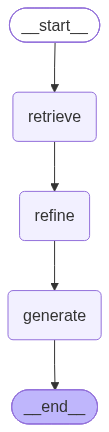

In [35]:
g = StateGraph(State)
g.add_node("retrieve", retrieve)
g.add_node("refine", refine)
g.add_node("generate", generate)

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "refine")
g.add_edge("refine", "generate")
g.add_edge("generate", END)

app = g.compile()
app

In [36]:
res = app.invoke({
    "question": "Explain the bias–variance tradeoff",
    "docs": [],
    "strips": [],
    "kept_strips": [],
    "refined_context": "",
    "answer": ""
})
print(res["answer"])

- **Bias (under‑fitting)** – When the model is too simple (high bias), it cannot capture the underlying patterns in the data.  
  - Example: “Everybody who owns a house buys a boat.”  
  - The model performs poorly even on the training set because it ignores important variability in the data.

- **Variance (over‑fitting)** – When the model is too complex (high variance), it fits the training data’s particularities instead of the true underlying rule.  
  - Example: a rule that depends on age, number of children, and marital status that matches every training example but will not hold for new customers.  
  - The model predicts well on the training set but fails to generalize to new data.

- **Trade‑off** – Increasing model complexity reduces bias (better fit to training data) but raises variance (worse generalization). Decreasing complexity does the opposite.  
  - There is a **sweet spot** where bias and variance are balanced, giving the best generalization performance.

- **Relation 

In [37]:
print(res['docs'][0].page_content)
print('*'*100)
print(res['docs'][1].page_content)
print('*'*100)
print(res['docs'][2].page_content)
print('*'*100)
print(res['docs'][3].page_content)

Figure 2-1. Trade-off of model complexity against training and test accuracy
Relation of Model Complexity to Dataset Size
It’s important to note that model complexity is intimately tied to the variation of
inputs contained in your training dataset: the larger variety of data points your data‐
set contains, the more complex a model you can use without overfitting. Usually, col‐
lecting more data points will yield more variety, so larger datasets allow building
more complex models. However, simply duplicating the same data points or collect‐
ing very similar data will not help.
Going back to the boat selling example, if we saw 10,000 more rows of customer data,
and all of them complied with the rule “If the customer is older than 45, and has less
than 3 children or is not divorced, then they want to buy a boat, ” we would be much
****************************************************************************************************
occurs when you fit a model too closely to the particularit

### ***Retrieval Evaluator***
- ***A Retrieval Evaluator is a quality control gate in a RAG pipeline that assesses whether top-k retrieved chunks actually contain the information needed to answer the user's query***.

- ***By scoring retrieved context against a threshold, it acts as a router—triggering downstream steps like document refinement if the retrieval is good, or falling back to web search or query rewriting if the retrieval is poor.***

In [38]:
UPPER_TH = 0.7
LOWER_TH = 0.3


class State(TypedDict):
    question: str
    docs: List[Document]

    good_docs: List[Document]
    verdict: str
    reason: str

    strips: List[str]
    kept_strips: List[str]
    refined_context: str
    
    answer: str


def retrieve_node(state: State) -> State:
    q = state["question"]
    return {"docs": retriever.invoke(q)}

In [39]:
# Score Based Doc Evluator 
class DocEvalScore(BaseModel):
    score: float
    reason: str

doc_eval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict retrieval evaluator for RAG.\n"
            "You will be given ONE retrieved chunk and a question.\n"
            "Return a relevance score in [0.0, 1.0].\n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly\n"
            "- 0.0: chunk is irrelevant\n"
            "Be conservative with high scores.\n"
            "Also return a short reason.\n"
            "Output JSON only.",
        ),
        ("human", "Question: {question}\n\nChunk:\n{chunk}"),
    ]
)

doc_eval_chain = doc_eval_prompt | llm1.with_structured_output(DocEvalScore)

In [40]:
def eval_each_doc_node(state: State) -> State:

    q = state["question"]
    
    scores: List[float] = []
    reasons: List[str] = []
    good: List[Document] = []

    for d in state["docs"]:
        out = doc_eval_chain.invoke({"question": q, "chunk": d.page_content})
        scores.append(out.score)
        reasons.append(out.reason)

        # 5) for CORRECT case we will refine only docs with score > LOWER_TH
        if out.score > LOWER_TH:
            good.append(d)

    # 2) CORRECT if at least one doc > UPPER_TH
    if any(s > UPPER_TH for s in scores):
        return {
            "good_docs": good,
            "verdict": "CORRECT",
            "reason": f"At least one retrieved chunk scored > {UPPER_TH}.",
        }

    # 3) INCORRECT if all docs < LOWER_TH
    if len(scores) > 0 and all(s < LOWER_TH for s in scores):
        why = "No chunk was sufficient."
        return {
            "good_docs": [],
            "verdict": "INCORRECT",
            "reason": f"All retrieved chunks scored < {LOWER_TH}. {why}",
        }

    # 4) Anything in between => AMBIGUOUS
    why = "Mixed relevance signals."
    return {
        "good_docs": good,
        "verdict": "AMBIGUOUS",
        "reason": f"No chunk scored > {UPPER_TH}, but not all were < {LOWER_TH}. {why}",
    }

In [41]:
# Sentence-Level Decomposer 
import re 
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

In [43]:
class KeepOrDrop(BaseModel):
    keep: bool

filter_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use ONLY the sentence. Output JSON only.",
        ),
        ("human", "Question: {question}\n\nSentence:\n{sentence}"),
    ]
)

filter_chain = filter_prompt | llm1.with_structured_output(KeepOrDrop)

# REFINING (Decompose -> Filter -> Recompose)
def refine(state: State) -> State:
    q = state["question"]

    # Combine retrieved docs into one context string
    # 5) In CORRECT case, eval node populates good_docs with docs having score > LOWER_TH
    context = "\n\n".join(d.page_content for d in state["good_docs"]).strip()

    # 1) DECOMPOSITION: context -> sentence strips
    strips = decompose_to_sentences(context)

    # 2) FILTER: keep only relevant strips
    kept: List[str] = []
    for s in strips:
        if filter_chain.invoke({"question": q, "sentence": s}).keep:
            kept.append(s)

    # 3) RECOMPOSE: glue kept strips back together (internal knowledge)
    refined_context = "\n".join(kept).strip()

    return {
        "strips": strips,
        "kept_strips": kept,
        "refined_context": refined_context,
    }

In [55]:
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided context.\n"
            "If the context is empty or insufficient, say: 'I don't know.'",
        ),
        ("human", "Question: {question}\n\nRefined context:\n{refined_context}"),
    ]
)

def generate(state: State) -> State:
    out = (answer_prompt | llm1).invoke(
        {"question": state["question"], "refined_context": state["refined_context"]}
    )
    return {"answer": out.content}

In [56]:
def fail_node(state: State) -> State:
    return {"answer": f"FAIL: {state['reason']}"}

def ambiguous_node(state: State) -> State:
    return {"answer": f"Ambiguous: {state['reason']}"}

def route_after_eval(state: State) -> str:
    if state["verdict"] == "CORRECT":
        return "refine"
    elif state["verdict"] == "INCORRECT":
        return "web_search"
    else:
        return "ambiguous"

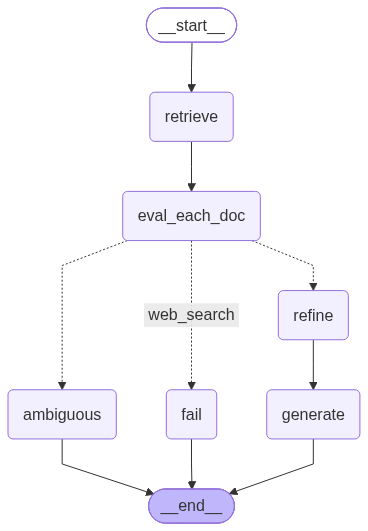

In [57]:
g = StateGraph(State)
g.add_node("retrieve", retrieve_node)
g.add_node("eval_each_doc", eval_each_doc_node)
g.add_node("refine", refine)
g.add_node("generate", generate)
g.add_node("fail", fail_node)
g.add_node("ambiguous", ambiguous_node)


g.add_edge(START, "retrieve")
g.add_edge("retrieve", "eval_each_doc")

g.add_conditional_edges(
    "eval_each_doc",
    route_after_eval,
    {"refine": "refine", "web_search": "fail", "ambiguous": "ambiguous"}
)
g.add_edge("refine", "generate")
g.add_edge("generate", END)
g.add_edge("fail", END)

app = g.compile()
app

In [58]:
res = app.invoke(
    {
        "question": "What are Transformers & why they important ",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
print("\nOUTPUT:\n", res["answer"])

VERDICT: INCORRECT
REASON: All retrieved chunks scored < 0.3. No chunk was sufficient.

OUTPUT:
 FAIL: All retrieved chunks scored < 0.3. No chunk was sufficient.


### ***Web-Search Refinement***
- ***Web Search Refinement applies sentence-level filtering and context recomposition to external web search results during a RAG retrieval fallback.***

- ***When internal vector retrieval fails, web search provides fresh external data—but it often brings in heavy SEO noise, page headers, and fluff. Web Search Refinement takes the raw web snippets, decomposes them into sentences, strips out non-essential text via a lightweight LLM judge, and recomposes a minimal, dense context string for answer generation.***

In [90]:
class State(TypedDict):

    question: str
    docs: List[Document]

    good_docs: List[Document]
    verdict: str
    reason: str

    strips: List[str]
    kept_strips: List[str]
    refined_context: str

    web_docs: List[Document] 
    web_query: str         
    
    answer: str

def retrieve_node(state: State) -> State:
    q = state["question"]
    return {"docs": retriever.invoke(q)}

In [91]:
class DocEvalScore(BaseModel):
    score: float
    reason: str

doc_eval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict retrieval evaluator for RAG.\n"
            "You will be given ONE retrieved chunk and a question.\n"
            "Return a relevance score in [0.0, 1.0].\n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly\n"
            "- 0.0: chunk is irrelevant\n"
            "Be conservative with high scores.\n"
            "Also return a short reason.\n"
            "Output JSON only.",
        ),
        ("human", "Question: {question}\n\nChunk:\n{chunk}"),
    ]
)

doc_eval_chain = doc_eval_prompt | llm1.with_structured_output(DocEvalScore)

In [92]:
def eval_each_doc_node(state: State) -> State:
    q = state["question"]
    scores: List[float] = []
    good: List[Document] = []

    for d in state["docs"]:
        out = doc_eval_chain.invoke({"question": q, "chunk": d.page_content})
        scores.append(out.score)

        if out.score > LOWER_TH:
            good.append(d)

    if any(s > UPPER_TH for s in scores):
        return {
            "good_docs": good,
            "verdict": "CORRECT",
            "reason": f"At least one retrieved chunk scored > {UPPER_TH}.",
        }

    if len(scores) > 0 and all(s < LOWER_TH for s in scores):
        why = "No chunk was sufficient."
        return {
            "good_docs": [],
            "verdict": "INCORRECT",
            "reason": f"All retrieved chunks scored < {LOWER_TH}. {why}",
        }

    why = "Mixed relevance signals."
    return {
        "good_docs": good,
        "verdict": "AMBIGUOUS",
        "reason": f"No chunk scored > {UPPER_TH}, but not all were < {LOWER_TH}. {why}",
    }

In [93]:
# Sentence-level DECOMPOSER
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]


# FILTER (LLM judge)
class KeepOrDrop(BaseModel):
    keep: bool

filter_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use ONLY the sentence. Output JSON only.",
        ),
        ("human", "Question: {question}\n\nSentence:\n{sentence}"),
    ]
)

filter_chain = filter_prompt | llm1.with_structured_output(KeepOrDrop)


# REFINING (Decompose -> Filter -> Recompose)
def refine(state: State) -> State:
    q = state["question"]

    if state.get("verdict") == "CORRECT":
        context = "\n\n".join(d.page_content for d in state["good_docs"]).strip()
    else:
        context = "\n\n".join(d.page_content for d in state["web_docs"]).strip()

    strips = decompose_to_sentences(context)

    kept: List[str] = []
    for s in strips:
        if filter_chain.invoke({"question": q, "sentence": s}).keep:
            kept.append(s)

    refined_context = "\n".join(kept).strip()

    return {
        "strips": strips,
        "kept_strips": kept,
        "refined_context": refined_context,
    }

In [94]:
class WebQuery(BaseModel):
    query: str


rewrite_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "Rewrite the user question into a web search query composed of keywords.\n"
        "Rules:\n"
        "- Keep it short (6–14 words).\n"
        "- If the question implies recency "
        "(e.g., recent/latest/last week/last month), "
        "add a constraint like (last 30 days).\n"
        "- Do NOT answer the question.\n"
        "- Return JSON with a single key: query"
    ),
    ("human", "Question: {question}")
])


rewrite_chain = (
    rewrite_prompt
    | llm1.with_structured_output(WebQuery)
)


def rewrite_query_node(state: State) -> State:

    out = rewrite_chain.invoke({
        "question": state["question"]
    })

    return {
        "web_query": out.query
    }

In [95]:
from langchain_tavily import TavilySearch
from langchain_core.documents import Document

tavily = TavilySearch(max_results=5)

def web_search_node(state: State) -> State:
    q = state["question"]
    response = tavily.invoke({
        "query": q
    })

    # Tavily returns a dictionary
    results = response.get("results", [])
    web_docs = []

    for r in results:
        title = r.get("title", "")
        url = r.get("url", "")
        content = (
            r.get("content", "")
            or r.get("snippet", "")
        )

        text = (
            f"TITLE: {title}\n"
            f"URL: {url}\n"
            f"CONTENT:\n{content}"
        )

        web_docs.append(
            Document(
                page_content=text,
                metadata={
                    "url": url,
                    "title": title
                }
            )
        )

    return {
        "web_docs": web_docs
    }

In [96]:
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided context.\n"
            "If the context is empty or insufficient, say: 'I don't know.'",
        ),
        ("human", "Question: {question}\n\nRefined context:\n{refined_context}"),
    ]
)
def generate(state: State) -> State:
    out = (answer_prompt | llm1).invoke(
        {"question": state["question"], "refined_context": state["refined_context"]}
    )
    return {"answer": out.content}


def ambiguous_node(state: State) -> State:
    return {"answer": f"Ambiguous: {state['reason']}"}
    

def route_after_eval(state: State) -> str:
    if state["verdict"] == "CORRECT":
        return "refine"
    elif state["verdict"] == "INCORRECT":
        return "web_search"
    else:
        return "ambiguous"

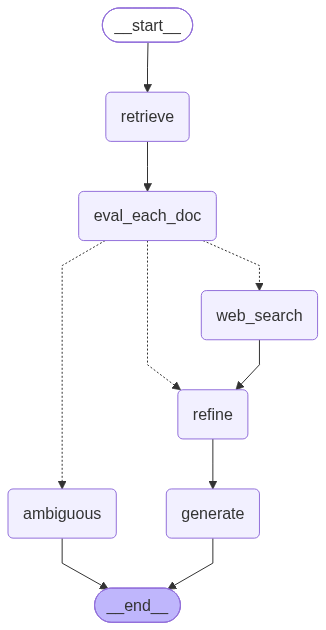

In [97]:
g = StateGraph(State)

g.add_node("retrieve", retrieve_node)
g.add_node("eval_each_doc", eval_each_doc_node)
g.add_node("web_search", web_search_node)
g.add_node("refine", refine)          # uses verdict to pick good_docs vs web_docs
g.add_node("generate", generate)
g.add_node("ambiguous", ambiguous_node)

# flow
g.add_edge(START, "retrieve")
g.add_edge("retrieve", "eval_each_doc")

# route after evaluation
g.add_conditional_edges(
    "eval_each_doc",
    route_after_eval,
    {
        "refine": "refine",          # CORRECT -> refine (good_docs)
        "web_search": "web_search",  # INCORRECT -> web_search
        "ambiguous": "ambiguous",    # AMBIGUOUS -> end (your current choice)
    },
)

# ✅ key change: web_search now goes through refine
g.add_edge("web_search", "refine")    # INCORRECT -> refine (web_docs)
g.add_edge("refine", "generate")      # CORRECT/INCORRECT -> generate

g.add_edge("generate", END)
g.add_edge("ambiguous", END)

app = g.compile()
app

In [98]:
res = app.invoke(
    {
        "question": "AI news from the last month",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "web_docs": [],   
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
print("\nOUTPUT:\n", res["answer"])

VERDICT: INCORRECT
REASON: All retrieved chunks scored < 0.3. No chunk was sufficient.

OUTPUT:
 **AI news from the last month (August 2026)**  

**HeadsUpAI – “Biggest AI News This Month (August 2026)”**  
1. **xAI – Imagine Image 2.0** – New version adds precision editing tools and ready‑made templates.  
2. **Discovery Loop** – Jeff Dean and Google researchers identified a fast‑growing AI startup they call “Discovery Loop.”  
3. **Google Gemini** – Google announced free one‑year access to Gemini for developers and rolled out new study‑tool integrations.  
4. **Cursor – Origin platform** – Cursor launched “Origin,” a code‑hosting service that syncs with GitHub.  
5. **Dario Amodei’s rebuttal** – The former OpenAI leader pushed back against claims that AI policy is being captured by regulators.  
6. **Warp Agent CLI** – Added the `/connect‑grok` command, letting users link an X Premium subscription to Grok.  
7. **Sakana AI – Namazu API** – Released a Japanese‑language API aimed at bu

In [100]:
res['question']

'AI news from the last month'